# 1.2 Exploración de P2: riesgo aproximado por capacidad

P2: ¿una estación estará en riesgo de quedarse sin bicicletas o sin anclajes en la siguiente hora? MiBici no publica inventario, así que el riesgo se **aproxima** con los viajes y la capacidad publicada. Prueba no se usa aquí.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from mibici_equipo39 import config as C
from mibici_equipo39.features import FEATURE_COLUMNS, load_p2_targets, load_tables, proxy_labels

metadata, X, _ = load_tables()
df = pd.concat([metadata, X, load_p2_targets()], axis=1)
df = df.loc[df["capacity"].notna()].reset_index(drop=True)
train = df["split"].eq("train").to_numpy()
val = df["split"].eq("validation").to_numpy()
print(df["station_id"].nunique(), "estaciones con capacidad válida,", len(df), "filas estación-hora")

469 estaciones con capacidad válida, 4018392 filas estación-hora


## Cómo se construye la etiqueta

In [2]:
example = pd.DataFrame({"capacidad": [20.0, 40.0, 20.0], "flujo_min": [-8, -8, 0], "flujo_max": [0, 0, 8]})
example["y_bikes"], example["y_docks"] = proxy_labels(example["flujo_min"], example["flujo_max"], example["capacidad"])
example

,capacidad,flujo_min,flujo_max,y_bikes,y_docks
0,20.0,-8,0,1,0
1,40.0,-8,0,0,0
2,20.0,0,8,0,1


> **Trayectoria y no flujo final.** Cada hora empieza con 50% de la capacidad y se suman llegadas y restan salidas evento por evento. Hay riesgo de bicicletas si en algún momento quedan 10% o menos, y de anclajes si se llega a 90%. Con el mínimo y el máximo se detecta una estación que se vacía a media hora aunque se recupere al final. Las mismas 8 salidas son riesgo con capacidad 20 y no con 40.

## Qué tan raras son

In [3]:
print("horas con los dos riesgos:", int((df["y_bikes"].eq(1) & df["y_docks"].eq(1)).sum()))
df.groupby("split")[["y_bikes", "y_docks"]].agg(["mean", "sum"]).round(4)

horas con los dos riesgos: 19


y_bikes        y_docks       
              mean    sum    mean    sum
split                                   
test        0.0038   2288  0.0050   3012
train       0.0039  11126  0.0051  14356
validation  0.0040   2324  0.0051   2971

> **Métricas.** Menos de 1% de las horas son positivas: un modelo que nunca alerta tendría 99% de exactitud y no serviría. Por eso se usan recall (riesgos detectados), precisión (alertas reales), F1 y AP, que resume toda la curva sin depender del umbral. La prevalencia es casi igual en los tres conjuntos porque la partición reparte días de todos los meses.

## Dónde y cuándo

,y_bikes,y_docks
estaciones_con_positivos,285.000,281.000
share_10pct_estaciones,0.592,0.664


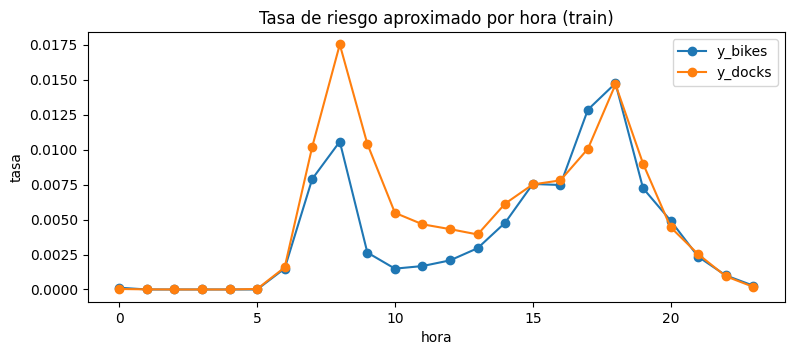

In [4]:
tr = df.loc[train]
concentration = {}
for target in ["y_bikes", "y_docks"]:
    per_station = tr.groupby("station_id", observed=True)[target].sum().sort_values(ascending=False)
    top = round(len(per_station) * 0.10)
    concentration[target] = {"estaciones_con_positivos": int((per_station > 0).sum()), "share_10pct_estaciones": round(per_station.head(top).sum() / per_station.sum(), 3)}
ax = tr.groupby("hour_of_day")[["y_bikes", "y_docks"]].mean().plot(figsize=(9, 3.5), marker="o", title="Tasa de riesgo aproximado por hora (train)")
ax.set(xlabel="hora", ylabel="tasa")
plt.savefig(C.FIGURES / "p2_tasa_por_hora.png", dpi=120, bbox_inches="tight")
pd.DataFrame(concentration)

In [5]:
tr.groupby(pd.cut(tr["capacity"], [0, 14, 15, 19, 40]), observed=True)[["y_bikes", "y_docks"]].mean().round(4)

,y_bikes,y_docks
capacity,,
"(0, 14]",0.0076,0.0069
"(14, 15]",0.0047,0.0070
"(15, 19]",0.0019,0.0022
"(19, 40]",0.0040,0.0053


> **Variables.** Un 10% de las estaciones junta más de la mitad de los positivos, así que el modelo necesita saber de qué estación se trata: `station_id` entra en one-hot. El riesgo tiene picos en horas de traslado, que entran por las variables de calendario. La capacidad no entra como predictor: es una foto de septiembre de 2026 y ya está dentro de la etiqueta. Tampoco entran rezagos, porque con días aleatorios un objetivo reservado reaparecería como variable de train.

## Sensibilidad a la ocupación inicial

In [6]:
rows = {}
for occupancy in [0.25, 0.50, 0.75]:
    bikes, docks = proxy_labels(df["flow_min"], df["flow_max"], df["capacity"], occupancy=occupancy)
    rows[occupancy] = {"prevalencia_bikes": bikes.mean(), "prevalencia_docks": docks.mean()}
pd.DataFrame(rows).T.round(4)

,prevalencia_bikes,prevalencia_docks
0.25,0.0552,0.0006
0.50,0.0039,0.0051
0.75,0.0004,0.0615


> **Es una aproximación.** Con 25% de ocupación inicial el riesgo de bicicletas pasa de 0.4% a más de 5%; con 75% pasa lo mismo con anclajes. Por eso las salidas se llaman `riesgo_proxy_bicicletas` y `riesgo_proxy_anclajes` y el puntaje sirve para ordenar estaciones, no como probabilidad real de desabasto.

## Baseline y candidato de la propuesta

In [7]:
numeric, categorical = list(FEATURE_COLUMNS), ["station_id"]
columns = numeric + categorical

def candidate():
    prep = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=True), categorical),
    ])
    return make_pipeline(prep, LogisticRegression(C=1.0, class_weight="balanced", solver="liblinear", max_iter=1000, random_state=C.SEED))

scores = {}
for risk, target in [("bikes", "y_bikes"), ("docks", "y_docks")]:
    scores[("dummy", risk)] = DummyClassifier(strategy="prior").fit(tr[columns], tr[target]).predict_proba(df[columns])[:, 1]
    scores[("logistica", risk)] = candidate().fit(tr[columns], tr[target]).predict_proba(df[columns])[:, 1]

## Búsqueda de umbral en validación

Rejilla de 0.05 a 0.95 de 0.05 en 0.05. Se queda el de mayor precisión entre los que detectan al menos 80% de los riesgos; si ninguno llega, el de mayor F1. En empate, el más alto.

In [8]:
grid = np.round(np.arange(0.05, 1.0, 0.05), 2)

def search(y, s):
    rows = []
    for t in grid:
        alert = s >= t
        tp = int((alert & (y == 1)).sum())
        precision = tp / alert.sum() if alert.sum() else 0.0
        recall = tp / (y == 1).sum()
        rows.append({"threshold": t, "precision": precision, "recall": recall,
                     "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0, "alert_rate": alert.mean()})
    return pd.DataFrame(rows)

def pick(table):
    ok = table[table["recall"] >= C.P2_MIN_RECALL]
    pool, col = (ok, "precision") if len(ok) else (table, "f1")
    return pool.loc[pool[col] == pool[col].max(), "threshold"].max(), "recall_floor" if len(ok) else "max_f1"

tables = {key: search(df[f"y_{key[1]}"].to_numpy()[val], s[val]) for key, s in scores.items()}
tables[("logistica", "bikes")].round(4)

,threshold,precision,recall,f1,alert_rate
0,0.05,0.0084,0.9953,0.0166,0.4710
1,0.10,0.0097,0.9905,0.0193,0.4040
2,0.15,0.0109,0.9828,0.0216,0.3574
3,0.20,0.0119,0.9785,0.0236,0.3252
4,0.25,0.0130,0.9712,0.0256,0.2974
5,0.30,0.0139,0.9634,0.0275,0.2743
6,0.35,0.0149,0.9531,0.0294,0.2535
7,0.40,0.0160,0.9398,0.0314,0.2337
8,0.45,0.0170,0.9230,0.0334,0.2155
9,0.50,0.0182,0.9058,0.0357,0.1973


In [9]:
summary = {}
n = df["station_id"].nunique()
for (model, risk), table in tables.items():
    t, rule = pick(table)
    row = table.loc[table["threshold"] == t].iloc[0]
    y = df[f"y_{risk}"].to_numpy()[val]
    ap = average_precision_score(y, scores[(model, risk)][val])
    summary[(model, risk)] = {"umbral": t, "regla": rule, "recall": row["recall"], "precision": row["precision"], "f1": row["f1"],
                              "ap": ap, "ap_vs_prevalencia": ap / y.mean(), "alertas_por_hora": row["alert_rate"] * n}
result = pd.DataFrame(summary).T
macro = result.groupby(level=0)["f1"].mean().rename("val_macro_f1")
display(result.round(4))
macro.round(4)

,,umbral,regla,recall,precision,f1,ap,ap_vs_prevalencia,alertas_por_hora
dummy,bikes,0.95,max_f1,0.0,0.0,0.0,0.003971,1.0,0.0
logistica,bikes,0.65,recall_floor,0.817986,0.02274,0.04425,0.039655,9.987253,66.983974
dummy,docks,0.95,max_f1,0.0,0.0,0.0,0.005076,1.0,0.0
logistica,docks,0.65,recall_floor,0.812184,0.030283,0.058389,0.098607,19.426435,63.847756


dummy            0.0
logistica    0.05132
Name: val_macro_f1, dtype: object

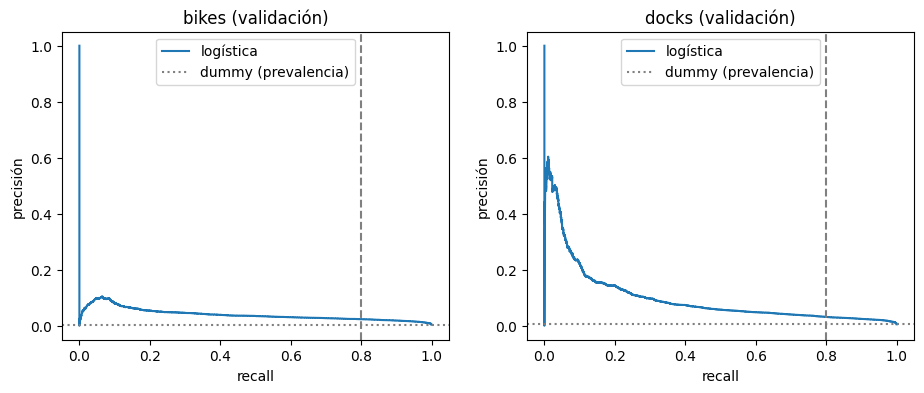

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, risk in zip(axes, ["bikes", "docks"]):
    y = df[f"y_{risk}"].to_numpy()[val]
    p, r, _ = precision_recall_curve(y, scores[("logistica", risk)][val])
    ax.plot(r, p, label="logística")
    ax.axhline(y.mean(), color="grey", linestyle=":", label="dummy (prevalencia)")
    ax.axvline(C.P2_MIN_RECALL, color="grey", linestyle="--")
    ax.set(title=f"{risk} (validación)", xlabel="recall", ylabel="precisión")
    ax.legend()
plt.savefig(C.FIGURES / "p2_comparacion_modelos.png", dpi=120, bbox_inches="tight")

> **Por qué estos modelos.**
> - **Baseline `DummyClassifier(prior)`:** predice la prevalencia de train para todos. Con la rejilla nunca alerta, así que su F1 es 0 y su AP es igual a la prevalencia. Es el piso: cualquier modelo útil tiene que ordenar mejor que el azar.
> - **Candidato, regresión logística:** es interpretable (cada estación y cada hora tienen su coeficiente), entrena en segundos y da un puntaje para ordenar visitas. `class_weight="balanced"` compensa que menos de 1% de las horas sean positivas y deja los puntajes en un rango donde la rejilla de 0.05 a 0.95 tiene sentido. Escalado e imputación van solo para las variables numéricas y one-hot para la estación, ajustados únicamente con train.
> - **Resultado:** la logística detecta más de 80% de los riesgos y su AP es de 10 a 20 veces la prevalencia, así que mejora `val_macro_f1` y se selecciona.

> **Límite honesto.** Con el umbral que asegura 80% de recall, solo de 2 a 3 de cada 100 alertas son riesgo según la etiqueta, y se marcan muchas estaciones por hora. Sirve para **ordenar** la ruta de rebalanceo, no para mandar camiones automáticamente. Lo que más subiría la precisión es agregar la presión reciente de cada estación (rezagos) con una partición temporal que no mezcle días reservados, y tener inventario real.

## Decisión

| | Elección |
|---|---|
| Baseline | `DummyClassifier(strategy="prior")` por etiqueta |
| Candidato | `SimpleImputer` + `StandardScaler` en calendario, `OneHotEncoder` en `station_id`, `LogisticRegression(C=1.0, class_weight="balanced", solver="liblinear", max_iter=1000, random_state=39)` por etiqueta |
| Umbral | Rejilla 0.05 a 0.95 en validación; mayor precisión con recall >= 0.80, si no mayor F1; empate al más alto |
| Regla | El candidato se queda si mejora `val_macro_f1`; prueba se mide una vez en MLflow sin reajustar el umbral |

Siguiente paso: `2.2-dm-p2-refactorizacion`.